# Replicate violins on a shared reference density scale

Each metric is saved as a separate PDF using a shared violin-width scale. `REFERENCE_DENSITY` fills the available width; * marks datasets with clipped violins. 

Widths encode density per score unit, so equal widths across different metric ranges do not imply equal plotted areas.


Observed, centroid, and peer distributions use their available scores independently. Paired delta summaries are computed in the metric notebooks.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.collections import PolyCollection
from scipy.stats import gaussian_kde


def find_repo_root(start=None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "results").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root from the current working directory.")


REPO_ROOT = find_repo_root()
RESULTS_DIR = REPO_ROOT / "results" / "replicate_signature_similarity_sep_rep"

# A KDE density of this many units (per unit score) fills the available width
# in every figure. Lower it to make all violins wider and clip more of them.
REFERENCE_DENSITY = 12.0
VIOLIN_WIDTH = 0.9
# Spacing between dataset groups, in units of one group. Raising it widens the
# gaps between datasets and the figure by the same factor, so violin widths are
# unchanged both in data units and on the page.
GROUP_PITCH = 1.3
GRID_SIZE = 512

HUE_ORDER = ["Cross replicate", "Centroid Baseline", "Peer Baseline"]
PALETTE = {
    "Cross replicate": "#dbe9f6",
    "Centroid Baseline": "#f4c7c3",
    "Peer Baseline": "#d9ead3",
}

DATASET_ORDER = [
    "cigs_mce",
    "cigs_tcm",
    "dilimap_train_val",
    "gdpx2",
    "l1000_phase1",
    "l1000_phase2",
    "novartis_batch_2500",
    "op3",
    "sciplex",
    "tahoe",
    "vcpi_0001",
    "vcpi_0002",
]
PRETTY_LABELS = {
    "l1000_phase1": "L1000 Phase I",
    "l1000_phase2": "L1000 Phase II",
    "tahoe": "Tahoe-100M",
    "cigs_mce": "CIGS-MCE",
    "novartis_batch_2500": "Novartis/DRUG-seq U2OS",
    "vcpi_0001": "VCPI-0001",
    "cigs_tcm": "CIGS-TCM",
    "vcpi_0002": "VCPI-0002",
    "gdpx2": "GDPx2",
    "sciplex": "sci-Plex",
    "dilimap_train_val": "DILImap",
    "op3": "OP3",
}

METRICS = {
    "signature": dict(
        source="condition_metric_summary.tsv",
        observed="mean_replicate_spearman_logfc",
        centroid="mean_replicate_baseline_spearman_logfc",
        peer="mean_peer_baseline_spearman_logfc",
        title="Replicate logFC Spearman",
        ylabel="Spearman(logFC)",
        pdf_name="refscale_signature_logfc_violin.pdf",
    ),
    "deg_lfc": dict(
        source="condition_deg_metric_summary.tsv",
        observed="mean_replicate_deg_lfc_spearman_sym_p05",
        centroid="mean_baseline_pair_deg_lfc_spearman_sym_p05",
        peer="mean_peer_baseline_deg_lfc_spearman_sym_p05",
        title="Replicate DEG-restricted logFC Spearman (adj.P.Value < 0.05)",
        ylabel="Score",
        pdf_name="refscale_deg_lfc_spearman_p05_violin.pdf",
    ),
    "direction": dict(
        source="condition_deg_metric_summary.tsv",
        observed="mean_replicate_direction_agreement_p05",
        centroid="mean_baseline_pair_direction_agreement_p05",
        peer="mean_peer_baseline_direction_agreement_p05",
        title="Replicate direction agreement (adj.P.Value < 0.05)",
        ylabel="Score",
        pdf_name="refscale_direction_agreement_p05_violin.pdf",
    ),
}

sns.set_theme(style="whitegrid", context="talk")
print(f"Reading from {RESULTS_DIR}")

Reading from /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep


In [2]:
def load_metric(spec: dict) -> pd.DataFrame:
    """One score per row, stacked over the three score types."""
    columns = ["dataset_name", spec["observed"], spec["centroid"], spec["peer"]]
    frame = pd.read_csv(RESULTS_DIR / spec["source"], sep="\t", usecols=columns)
    # Filter each score independently below, retaining baseline-only conditions.
    parts = []
    for key, hue in zip(("observed", "centroid", "peer"), HUE_ORDER):
        part = frame.loc[frame[spec[key]].notna(), ["dataset_name", spec[key]]]
        part = part.rename(columns={spec[key]: "score"})
        part["score_type"] = hue
        parts.append(part)
    violin_frame = pd.concat(parts, ignore_index=True)
    violin_frame["dataset_label"] = violin_frame["dataset_name"].map(PRETTY_LABELS)
    return violin_frame


def peak_densities(violin_frame: pd.DataFrame) -> pd.Series:
    """Largest KDE value per (dataset, score type), using Seaborn's KDE settings."""
    peaks = {}
    for key, group in violin_frame.groupby(["dataset_label", "score_type"], sort=False):
        values = group["score"].to_numpy(dtype=float)
        values = values[np.isfinite(values)]
        if len(values) < 2 or values.std(ddof=1) == 0:
            continue
        kde = gaussian_kde(values, bw_method="scott")
        peaks[key] = kde(np.linspace(values.min(), values.max(), GRID_SIZE)).max()
    return pd.Series(peaks, name="peak_density")


def cap_violin_widths(ax, *, cap_fraction, n_hues, width):
    """Scale every violin by 1/cap_fraction, then clamp it at its slot half-width.

    Returns the category indices that had at least one clipped violin.
    """
    slot_halfwidth = (width / n_hues) / 2
    capped = set()
    for collection in ax.collections:
        if not isinstance(collection, PolyCollection):
            continue
        for path in collection.get_paths():
            vertices = path.vertices
            center = 0.5 * (vertices[:, 0].min() + vertices[:, 0].max())
            offset = (vertices[:, 0] - center) / cap_fraction
            if np.abs(offset).max() > slot_halfwidth:
                capped.add(int(round(center)))
            vertices[:, 0] = center + np.clip(offset, -slot_halfwidth, slot_halfwidth)
    return capped


def spread_dataset_groups(ax, *, pitch, n_categories):
    """Move the dataset groups apart, leaving every violin's width untouched.

    Seaborn's own spacing knobs (``width``, ``gap``) buy room between groups by
    shrinking the violins, which would rescale the shared density axis. Shifting
    whole groups instead leaves widths, and therefore the scale, unchanged.
    """
    if pitch == 1.0:
        return
    for collection in ax.collections:
        if not isinstance(collection, PolyCollection):
            continue
        for path in collection.get_paths():
            vertices = path.vertices
            center = 0.5 * (vertices[:, 0].min() + vertices[:, 0].max())
            vertices[:, 0] += (pitch - 1.0) * round(center)
    # Seaborn draws constant-score groups as Line2D dashes, not polygons.
    # Move those dashes with their dataset while preserving their widths.
    for line in ax.lines:
        x = np.asarray(line.get_xdata(), dtype=float)
        if x.size == 0:
            continue
        center = 0.5 * (x.min() + x.max())
        line.set_xdata(x + (pitch - 1.0) * round(center))
    ax.set_xlim(-0.5 * pitch, (n_categories - 0.5) * pitch)


def plot_metric(
    violin_frame: pd.DataFrame,
    spec: dict,
    cap_fraction: float,
    *,
    width=VIOLIN_WIDTH,
    pitch=GROUP_PITCH,
):
    """Save a metric figure and a CSV of its input-score means and counts."""
    present = set(violin_frame["dataset_name"])
    order = [PRETTY_LABELS[name] for name in DATASET_ORDER if name in present]
    fig_width = max(10.0, 1.35 * pitch * len(order) + 2.0)
    fig, ax = plt.subplots(figsize=(fig_width, 6.4))

    sns.violinplot(
        data=violin_frame,
        x="dataset_label",
        y="score",
        hue="score_type",
        order=order,
        hue_order=HUE_ORDER,
        density_norm="area",
        common_norm=True,
        width=width,
        dodge=True,
        gap=0,
        inner=None,
        cut=0,
        gridsize=GRID_SIZE,
        linewidth=1.0,
        palette=PALETTE,
        ax=ax,
    )

    capped = cap_violin_widths(ax, cap_fraction=cap_fraction, n_hues=len(HUE_ORDER), width=width)
    spread_dataset_groups(ax, pitch=pitch, n_categories=len(order))
    ax.set_xticks([index * pitch for index in range(len(order))])
    ax.set_xticklabels([f"{label} *" if i in capped else label for i, label in enumerate(order)])
    ax.grid(axis="x", visible=False)
    if ax.get_legend() is not None:
        ax.legend(title="", loc="lower right", frameon=True)
    ax.set_title(spec["title"])
    ax.set_xlabel("")
    ax.set_ylabel(spec["ylabel"])
    ax.tick_params(axis="x", rotation=35)
    sns.despine(ax=ax)
    fig.tight_layout()

    out_path = RESULTS_DIR / spec["pdf_name"]
    png_path = out_path.with_suffix(".png")
    # Export means of the input scores, independent of KDE scaling or capping.
    csv_path = out_path.with_name(f"{out_path.stem}_means.csv")
    means_summary = (
        violin_frame.groupby(["dataset_name", "dataset_label", "score_type"], as_index=False)
        .agg(mean_score=("score", "mean"), n_scores=("score", "count"))
    )
    means_summary["_dataset_order"] = means_summary["dataset_name"].map(
        {name: index for index, name in enumerate(DATASET_ORDER)}
    )
    means_summary["_score_order"] = means_summary["score_type"].map(
        {name: index for index, name in enumerate(HUE_ORDER)}
    )
    means_summary = (
        means_summary.sort_values(["_dataset_order", "_score_order"])
        .drop(columns=["_dataset_order", "_score_order"])
        .reset_index(drop=True)
    )
    means_summary.to_csv(csv_path, index=False)
    fig.savefig(out_path, bbox_inches="tight")
    fig.savefig(png_path, bbox_inches="tight", dpi=200)
    plt.show()
    print(f"Saved plot to {out_path} and {png_path.name}")
    print(f"Saved score means and counts to {csv_path}")
    if capped:
        print("Width capped (marked *) in:", ", ".join(order[i] for i in sorted(capped)))
    return order, capped

In [3]:
violin_frames = {key: load_metric(spec) for key, spec in METRICS.items()}
metric_peaks = {key: peak_densities(frame) for key, frame in violin_frames.items()}
cap_fractions = {key: REFERENCE_DENSITY / peaks.max() for key, peaks in metric_peaks.items()}

slot_width = VIOLIN_WIDTH / len(HUE_ORDER)
scale_table = pd.DataFrame(
    [
        {
            "metric": key,
            "n_violins": len(metric_peaks[key]),
            "global_peak_density": metric_peaks[key].max(),
            "median_peak_density": metric_peaks[key].median(),
            "cap_fraction": cap_fractions[key],
            "width_per_unit_density": slot_width / (cap_fractions[key] * metric_peaks[key].max()),
            "n_above_reference": int((metric_peaks[key] > REFERENCE_DENSITY).sum()),
        }
        for key in METRICS
    ]
)
print(f"Reference density {REFERENCE_DENSITY:g} fills the available width in every figure.")
print("'width_per_unit_density' is identical across metrics when the scale is shared.\n")
display(scale_table)

Reference density 12 fills the available width in every figure.
'width_per_unit_density' is identical across metrics when the scale is shared.



,metric,n_violins,global_peak_density,median_peak_density,cap_fraction,width_per_unit_density,n_above_reference
0,signature,36,219.171192,9.681962,0.054752,0.025,14
1,deg_lfc,36,7.242876,1.677416,1.656800,0.025,0
2,direction,35,90.024534,6.919914,0.133297,0.025,10


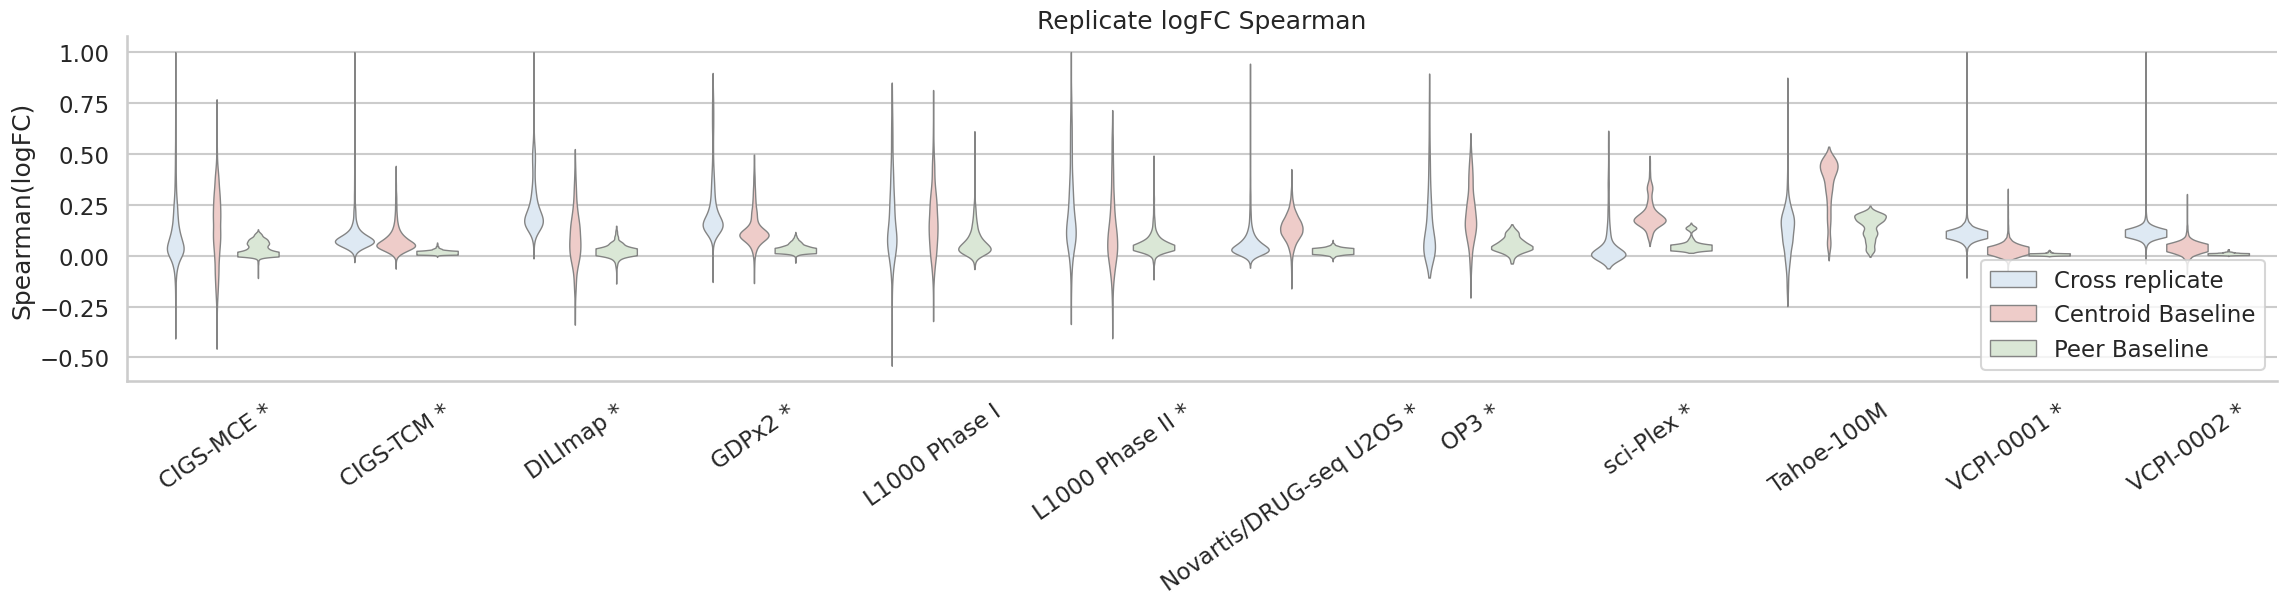

Saved plot to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep/refscale_signature_logfc_violin.pdf and refscale_signature_logfc_violin.png
Saved score means and counts to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep/refscale_signature_logfc_violin_means.csv
Width capped (marked *) in: CIGS-MCE, CIGS-TCM, DILImap, GDPx2, L1000 Phase II, Novartis/DRUG-seq U2OS, OP3, sci-Plex, VCPI-0001, VCPI-0002


In [4]:
signature_order, signature_capped = plot_metric(
    violin_frames["signature"], METRICS["signature"], cap_fractions["signature"]
)

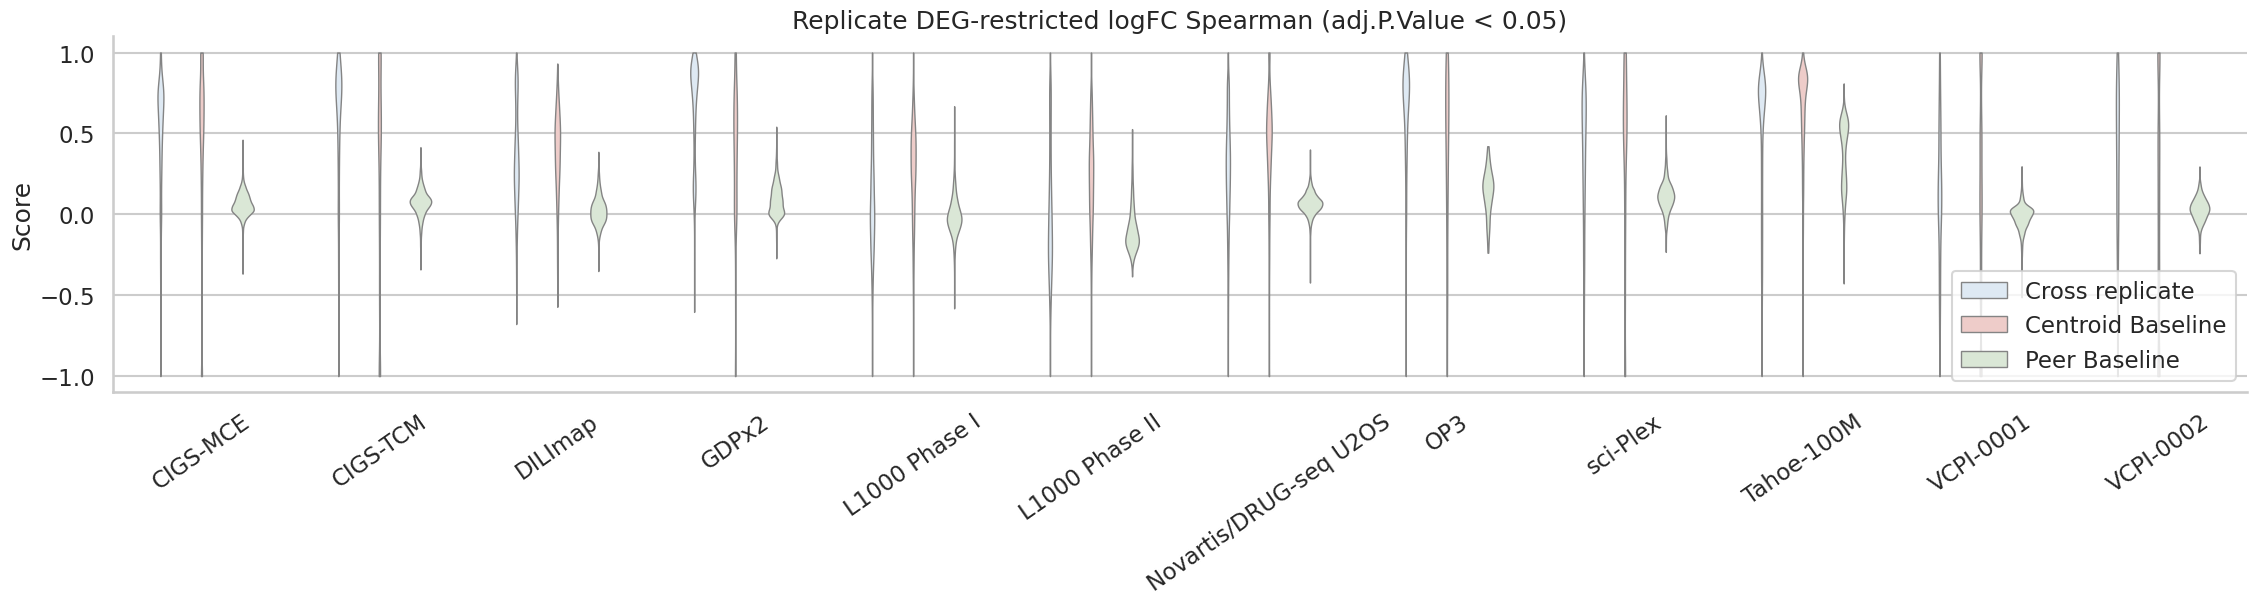

Saved plot to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep/refscale_deg_lfc_spearman_p05_violin.pdf and refscale_deg_lfc_spearman_p05_violin.png
Saved score means and counts to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep/refscale_deg_lfc_spearman_p05_violin_means.csv


In [5]:
deg_lfc_order, deg_lfc_capped = plot_metric(
    violin_frames["deg_lfc"], METRICS["deg_lfc"], cap_fractions["deg_lfc"]
)

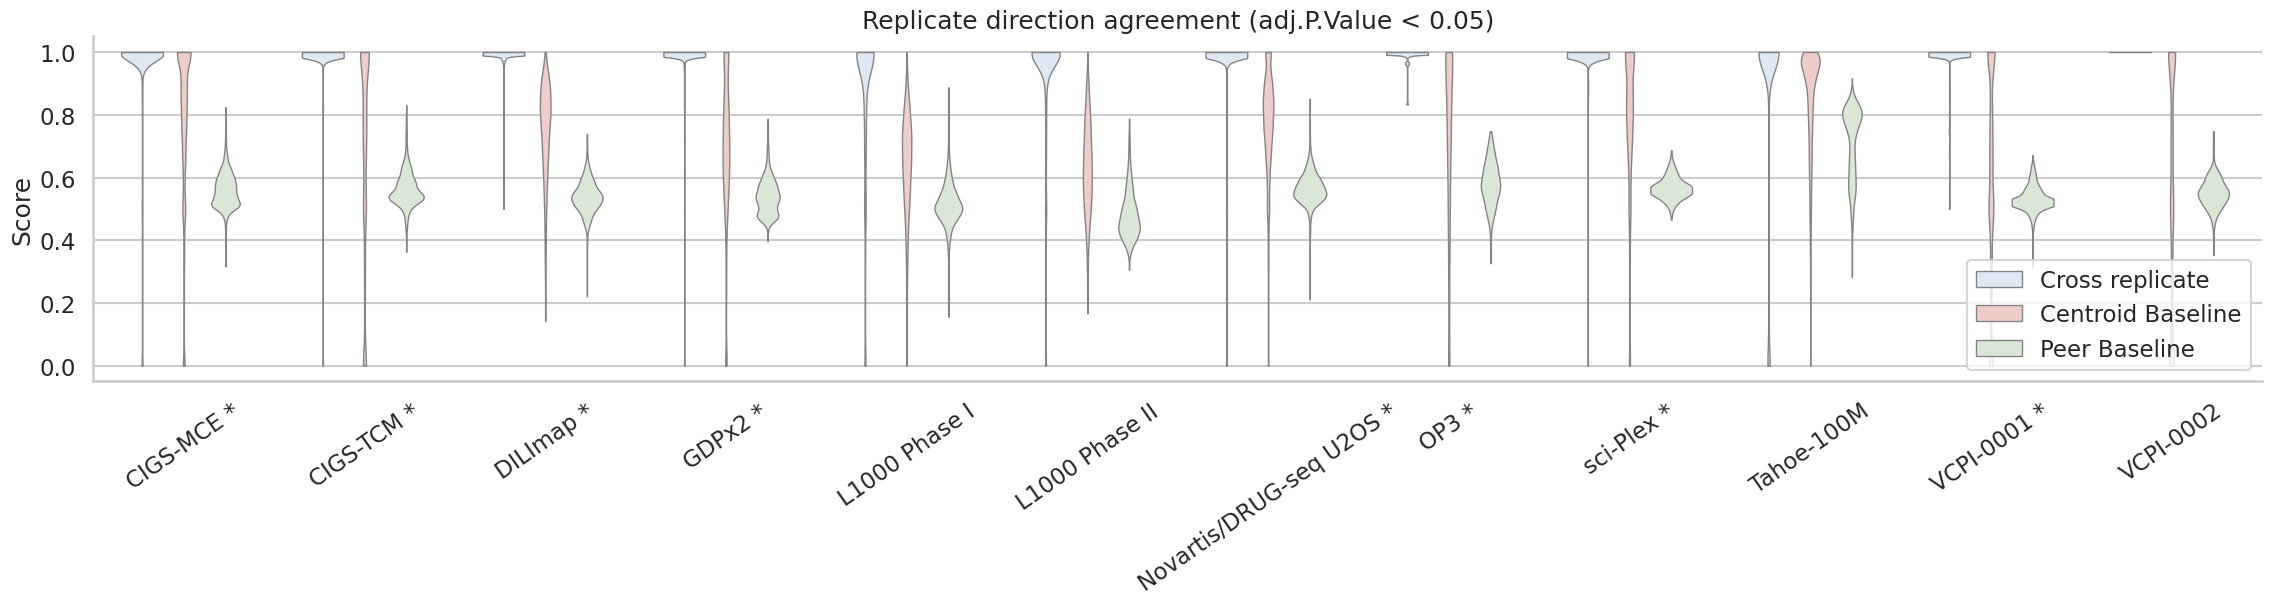

Saved plot to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep/refscale_direction_agreement_p05_violin.pdf and refscale_direction_agreement_p05_violin.png
Saved score means and counts to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep/refscale_direction_agreement_p05_violin_means.csv
Width capped (marked *) in: CIGS-MCE, CIGS-TCM, DILImap, GDPx2, Novartis/DRUG-seq U2OS, OP3, sci-Plex, VCPI-0001


In [6]:
direction_order, direction_capped = plot_metric(
    violin_frames["direction"], METRICS["direction"], cap_fractions["direction"]
)